# BÀI THỰC HÀNH 1 - BÀI 2 (TRANG 15 - 17)
## MÔN: KHAI PHÁ DỮ LIỆU
**Họ và tên:** Nguyễn Văn Hưng  
**MSSV:** 6451071029  
**Lớp:** CNTT.k64  
**Tập dữ liệu:** Titanic Disaster Dataset (`titanic.csv`)


In [1]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# Khởi tạo các thư viện cần thiết
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

# Cấu hình hiển thị đầy đủ tất cả các cột
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print("Các thư viện đã được nạp thành công!")


Nguyễn Văn Hưng - 6451071029
Các thư viện đã được nạp thành công!


### Câu 1: Nhập dữ liệu và thống kê những thông tin cơ bản của các thuộc tính
- Đọc dữ liệu `titanic.csv`
- Xem 10 dòng đầu bằng `head(10)`
- Xem thông tin tổng quan các cột và kiểu dữ liệu bằng `info()`
- Thống kê các chỉ số định lượng cơ bản bằng `describe()`


In [2]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 1. Nhập dữ liệu
with open('titanic.csv') as f:
    df = pd.read_csv(f, dtype={'age': np.float64, 'sibsp': np.int64, 'parch': np.int64})

print("1. 10 dòng đầu tiên của tập dữ liệu:")
display(df.head(10))

print("\n2. Thông tin cấu trúc dữ liệu:")
df.info()

print("\n3. Thống kê chỉ số các thuộc tính định lượng:")
display(df.describe())


Nguyễn Văn Hưng - 6451071029
1. 10 dòng đầu tiên của tập dữ liệu:
   pclass  survived                                             name     sex      age  sibsp  parch    ticket      fare    cabin embarked boat   body                        home.dest
0       1         1                    Allen, Miss. Elisabeth Walton  female  29.0000      0      0     24160  211.3375       B5        S    2    NaN                     St Louis, MO
1       1         1                   Allison, Master. Hudson Trevor    male   0.9167      1      2    113781  151.5500  C22 C26        S   11    NaN  Montreal, PQ / Chesterville, ON
2       1         0                     Allison, Miss. Helen Loraine  female   2.0000      1      2    113781  151.5500  C22 C26        S  NaN    NaN  Montreal, PQ / Chesterville, ON
3       1         0             Allison, Mr. Hudson Joshua Creighton    male  30.0000      1      2    113781  151.5500  C22 C26        S  NaN  135.0  Montreal, PQ / Chesterville, ON
4       1         0

### Câu 2: Liệt kê danh sách 5 thuộc tính có số lượng giá trị rỗng nhiều nhất
- Tính số lượng giá trị thiếu (`isnull().sum()`)
- Tính tỷ lệ phần trăm thiếu trên tổng số dòng
- Liệt kê top 5 thuộc tính thiếu nhiều nhất


In [3]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 2. Liệt kê top 5 thuộc tính có nhiều giá trị rỗng nhất
total = df.isnull().sum().sort_values(ascending=False)
percent_1 = df.isnull().sum() / df.isnull().count() * 100
percent_2 = (round(percent_1, 1)).sort_values(ascending=False)
missing_data = pd.concat([total, percent_2], axis=1, keys=['Total', '%'])

print("Top 5 thuộc tính có số lượng giá trị rỗng nhiều nhất:")
display(missing_data.head(5))

print("""
Nhận xét:
- Thuộc tính 'body' có tỷ lệ thiếu cao nhất lên tới 90.8% (1188 dòng trống).
- Thuộc tính 'cabin' thiếu 77.5% (1014 dòng trống).
- Thuộc tính 'boat' thiếu 62.9% (823 dòng trống).
- Thuộc tính 'home.dest' thiếu 43.1% (564 dòng trống).
- Thuộc tính 'age' thiếu 20.1% (263 dòng trống).
Việc thiếu dữ liệu nghiêm trọng ở 'body', 'cabin', 'boat' sẽ gây ảnh hưởng lớn nếu sử dụng trực tiếp, do đó cần loại bỏ hoặc xử lý phù hợp.""")


Nguyễn Văn Hưng - 6451071029
Top 5 thuộc tính có số lượng giá trị rỗng nhiều nhất:
           Total     %
body        1188  90.8
cabin       1014  77.5
boat         823  62.9
home.dest    564  43.1
age          263  20.1

Nhận xét:
- Thuộc tính 'body' có tỷ lệ thiếu cao nhất lên tới 90.8% (1188 dòng trống).
- Thuộc tính 'cabin' thiếu 77.5% (1014 dòng trống).
- Thuộc tính 'boat' thiếu 62.9% (823 dòng trống).
- Thuộc tính 'home.dest' thiếu 43.1% (564 dòng trống).
- Thuộc tính 'age' thiếu 20.1% (263 dòng trống).
Việc thiếu dữ liệu nghiêm trọng ở 'body', 'cabin', 'boat' sẽ gây ảnh hưởng lớn nếu sử dụng trực tiếp, do đó cần loại bỏ hoặc xử lý phù hợp.


### Câu 3: Khảo sát sự liên quan giữa Độ tuổi (age), Giới tính (sex) và Khả năng sống sót (survived)
- Trực quan hóa bằng histogram phân bố tuổi cho cả 2 giới tính Nam (Male) và Nữ (Female) theo trạng thái sống sót / không sống sót.
- Đưa ra nhận xét chi tiết.


Nguyễn Văn Hưng - 6451071029

Nhận xét:
1. Xác suất nam giới sống sót cao nhất ở độ tuổi trẻ em từ 1 đến 10 tuổi.
2. Nữ giới có cơ hội sống sót vượt trội ở hầu hết các nhóm tuổi (đặc biệt từ 15 đến 40 tuổi).
3. Nam giới trong độ tuổi thanh niên từ 18 đến 27 tuổi có tỷ lệ tử vong cao nhất.
4. Tổng quan: Tỷ lệ sống sót của nữ giới cao hơn nam giới rất nhiều (phù hợp với quy tắc ưu tiên cứu hộ 'Women and children first').


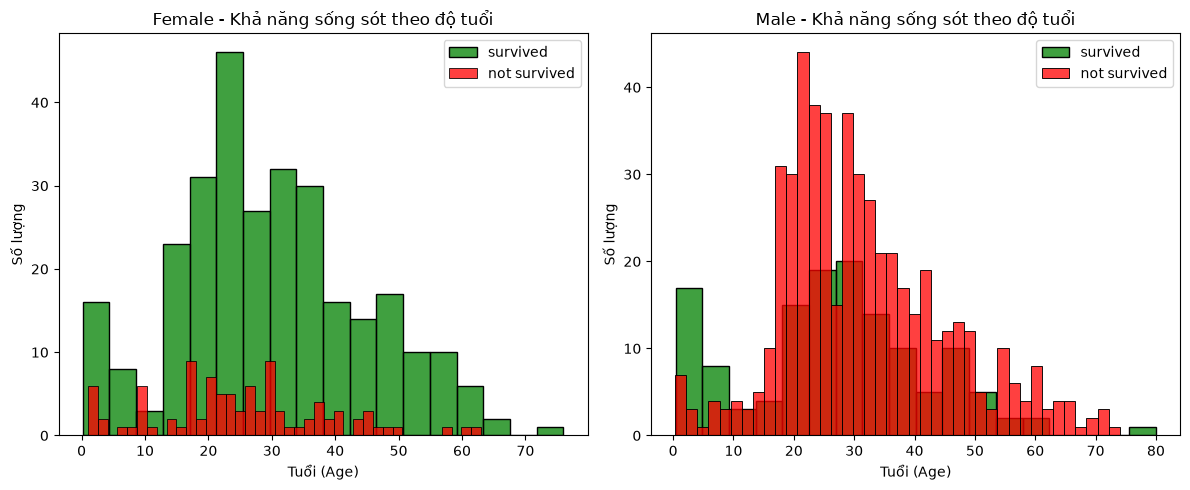

In [4]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 3. Khảo sát Độ tuổi (age), Giới tính (sex) và Sống sót (survived)
survived = 'survived'
not_survived = 'not survived'
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))
women = df[df['sex'] == 'female']
men = df[df['sex'] == 'male']

# Nữ (Female)
ax = sns.histplot(women[women['survived'] == 1].age.dropna(), bins=18, label=survived, ax=axes[0], kde=False, color='green')
ax = sns.histplot(women[women['survived'] == 0].age.dropna(), bins=40, label=not_survived, ax=axes[0], kde=False, color='red')
ax.legend()
ax.set_title('Female - Khả năng sống sót theo độ tuổi')
ax.set_xlabel('Tuổi (Age)')
ax.set_ylabel('Số lượng')

# Nam (Male)
ax = sns.histplot(men[men['survived'] == 1].age.dropna(), bins=18, label=survived, ax=axes[1], kde=False, color='green')
ax = sns.histplot(men[men['survived'] == 0].age.dropna(), bins=40, label=not_survived, ax=axes[1], kde=False, color='red')
ax.legend()
ax.set_title('Male - Khả năng sống sót theo độ tuổi')
ax.set_xlabel('Tuổi (Age)')
ax.set_ylabel('Số lượng')

plt.tight_layout()
plt.show()

print("""
Nhận xét:
1. Xác suất nam giới sống sót cao nhất ở độ tuổi trẻ em từ 1 đến 10 tuổi.
2. Nữ giới có cơ hội sống sót vượt trội ở hầu hết các nhóm tuổi (đặc biệt từ 15 đến 40 tuổi).
3. Nam giới trong độ tuổi thanh niên từ 18 đến 27 tuổi có tỷ lệ tử vong cao nhất.
4. Tổng quan: Tỷ lệ sống sót của nữ giới cao hơn nam giới rất nhiều (phù hợp với quy tắc ưu tiên cứu hộ 'Women and children first').""")


### Câu 4: Khảo sát sự liên quan giữa Cổng lên tàu (embarked) và Loại vé (pclass) với Khả năng sống sót (survived)
- Phân biệt theo Giới tính (sex) bằng `FacetGrid` / `pointplot`.
- Vẽ biểu đồ `barplot` thể hiện tỷ lệ sống sót theo hạng vé `pclass`.
- Rút ra nhận xét.


Nguyễn Văn Hưng - 6451071029

Nhận xét:
1. Cổng lên tàu (Embarked):
   - Phụ nữ lên tàu ở cổng Q và cổng S có tỷ lệ sống sót rất cao, trong khi lên ở cổng C có tỷ lệ sống sót thấp hơn đôi chút ở hạng 3.
   - Đàn ông lên tàu ở cổng C có tỷ lệ sống sót cao hơn rõ rệt so với nam giới lên tàu ở cổng S và Q.
2. Loại vé (Pclass):
   - Loại vé hạng 1 (Pclass = 1) có tỷ lệ sống sót cao nhất (khoảng trên 60%).
   - Loại vé hạng 3 (Pclass = 3) có tỷ lệ tử vong cao nhất (tỷ lệ sống sót chỉ đạt khoảng 25%).


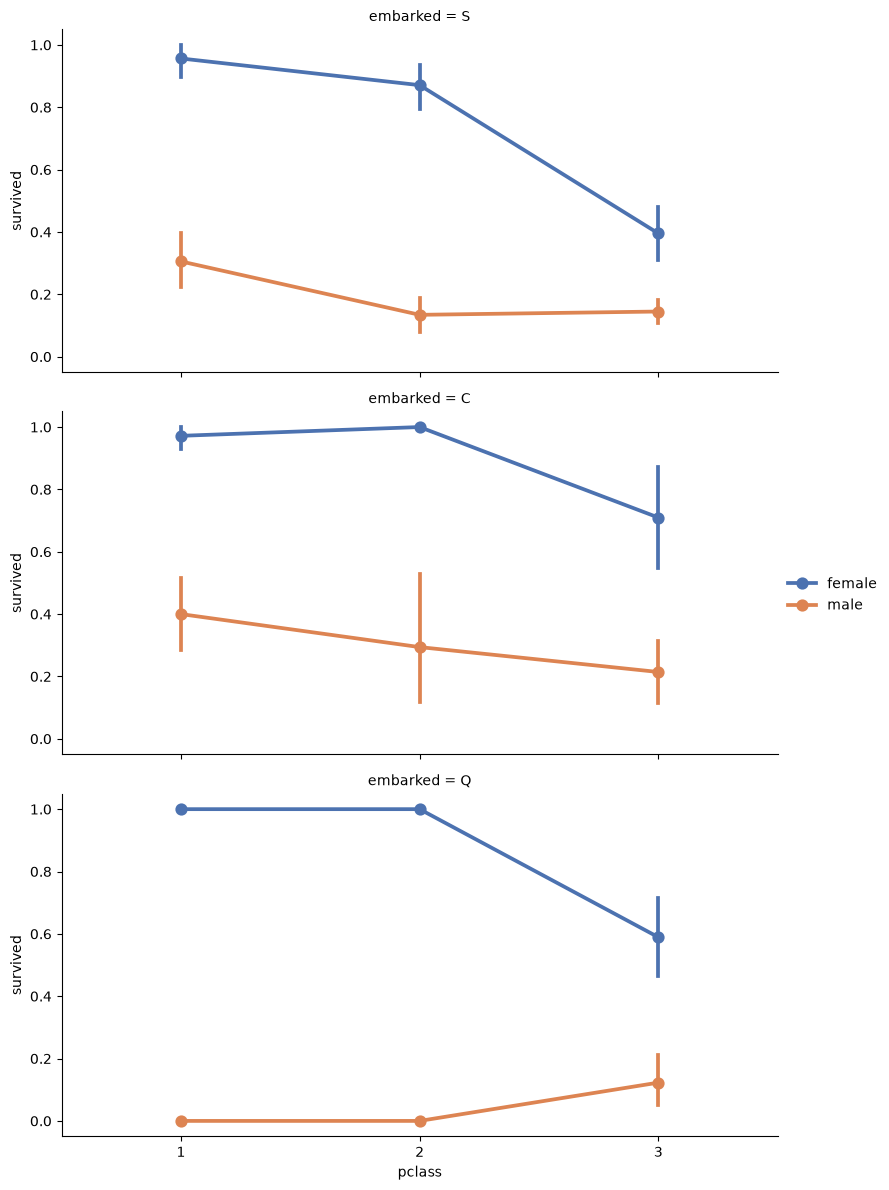

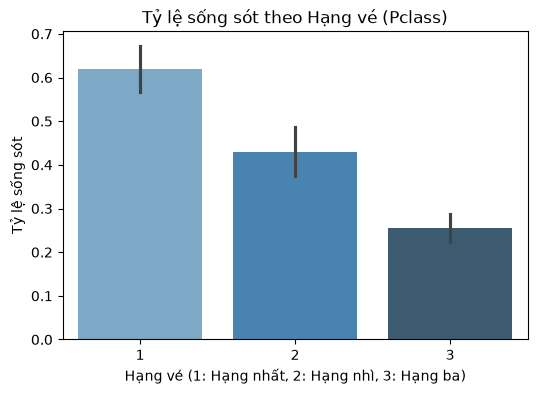

In [5]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 4. Cổng lên tàu (embarked), Hạng vé (pclass) và Sống sót (survived) theo Giới tính
FacetGrid = sns.FacetGrid(df, row='embarked', height=4, aspect=2)
FacetGrid.map(sns.pointplot, 'pclass', 'survived', 'sex', palette='deep', order=[1, 2, 3], hue_order=['female', 'male'])
FacetGrid.add_legend()
plt.show()

# Biểu đồ tỷ lệ sống sót theo Hạng vé (pclass)
plt.figure(figsize=(6, 4))
sns.barplot(x='pclass', y='survived', data=df, palette='Blues_d')
plt.title('Tỷ lệ sống sót theo Hạng vé (Pclass)')
plt.xlabel('Hạng vé (1: Hạng nhất, 2: Hạng nhì, 3: Hạng ba)')
plt.ylabel('Tỷ lệ sống sót')
plt.show()

print("""
Nhận xét:
1. Cổng lên tàu (Embarked):
   - Phụ nữ lên tàu ở cổng Q và cổng S có tỷ lệ sống sót rất cao, trong khi lên ở cổng C có tỷ lệ sống sót thấp hơn đôi chút ở hạng 3.
   - Đàn ông lên tàu ở cổng C có tỷ lệ sống sót cao hơn rõ rệt so với nam giới lên tàu ở cổng S và Q.
2. Loại vé (Pclass):
   - Loại vé hạng 1 (Pclass = 1) có tỷ lệ sống sót cao nhất (khoảng trên 60%).
   - Loại vé hạng 3 (Pclass = 3) có tỷ lệ tử vong cao nhất (tỷ lệ sống sót chỉ đạt khoảng 25%).""")


### Câu 5: Thống kê số người đi cùng và mối liên quan với khả năng sống sót
- Tạo biến `relatives = sibsp + parch`.
- Tạo biến `not_alone` (1 nếu đi một mình, 0 nếu có người thân đi cùng).
- Thống kê tần số và vẽ biểu đồ đường biểu diễn tỷ lệ sống sót theo số người đi cùng.


Nguyễn Văn Hưng - 6451071029
Số lượng hành khách đi một mình (1) và đi cùng người thân (0):
not_alone
1    790
0    519
Name: count, dtype: int64

Nhận xét:
- Số người đi một mình là 790 người; số người đi cùng người thân là 519 người.
- Hành khách có từ 1 đến 3 người thân đi cùng có cơ hội sống sót cao nhất (tỷ lệ sống sót đạt đỉnh ở mức 3 người thân: ~70%).
- Những người đi một mình (relatives = 0) hoặc gia đình quá đông (từ 4 người trở lên, đặc biệt 7-10 người) có tỷ lệ sống sót rất thấp.


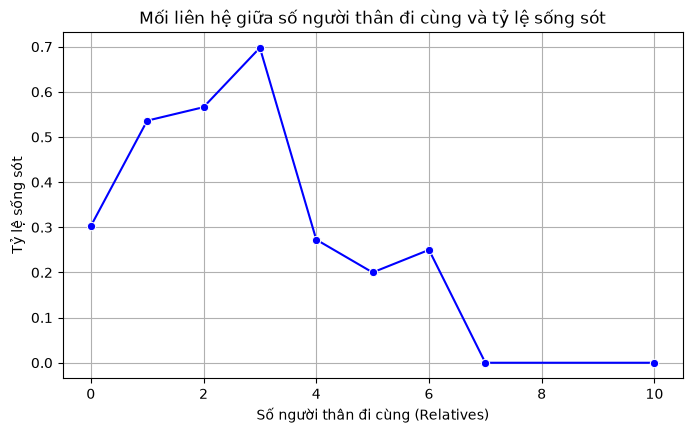

In [6]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 5. Thống kê số người đi cùng (SibSp + Parch)
data = [df]
for dataset in data:
    dataset['relatives'] = dataset['sibsp'] + dataset['parch']
    dataset.loc[dataset['relatives'] > 0, 'not_alone'] = 0
    dataset.loc[dataset['relatives'] == 0, 'not_alone'] = 1
    dataset['not_alone'] = dataset['not_alone'].astype(int)

print("Số lượng hành khách đi một mình (1) và đi cùng người thân (0):")
print(df['not_alone'].value_counts())

# Vẽ biểu đồ tương quan giữa số người đi cùng (relatives) và tỷ lệ sống sót
plt.figure(figsize=(8, 4.5))
sns.lineplot(x='relatives', y='survived', data=df, marker='o', color='b', ci=None)
plt.title('Mối liên hệ giữa số người thân đi cùng và tỷ lệ sống sót')
plt.xlabel('Số người thân đi cùng (Relatives)')
plt.ylabel('Tỷ lệ sống sót')
plt.grid(True)
plt.show()

print("""
Nhận xét:
- Số người đi một mình là 790 người; số người đi cùng người thân là 519 người.
- Hành khách có từ 1 đến 3 người thân đi cùng có cơ hội sống sót cao nhất (tỷ lệ sống sót đạt đỉnh ở mức 3 người thân: ~70%).
- Những người đi một mình (relatives = 0) hoặc gia đình quá đông (từ 4 người trở lên, đặc biệt 7-10 người) có tỷ lệ sống sót rất thấp.""")


### Câu 6: Tiền xử lý các thuộc tính thiếu dữ liệu và xóa bỏ thuộc tính không cần thiết
- Trích xuất chữ cái đầu tiên của `cabin` để tạo boong tàu (`deck`), sau đó mã hóa thành số.
- Xóa các cột rác hoặc thiếu dữ liệu nghiêm trọng: `cabin`, `ticket`, `boat`, `body`, `home.dest`.
- Điền dữ liệu thiếu cho `age` bằng giá trị ngẫu nhiên trong khoảng `[mean - std, mean + std]`.
- Điền dữ liệu thiếu cho `embarked` bằng giá trị xuất hiện nhiều nhất (mode = `'S'`).


In [7]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 6. Tiền xử lý thiếu dữ liệu và loại bỏ cột không cần thiết

# 6.1 Trích xuất thông tin boong tàu (deck) từ cabin
deck = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6, "G": 7, "U": 8}
for dataset in data:
    dataset['cabin'] = dataset['cabin'].fillna("U0")
    dataset['deck'] = dataset['cabin'].map(lambda x: re.compile("([a-zA-Z]+)").search(x).group())
    dataset['deck'] = dataset['deck'].map(deck)
    dataset['deck'] = dataset['deck'].fillna(0)
    dataset['deck'] = dataset['deck'].astype(int)

# Xóa các thuộc tính không cần thiết
df = df.drop(['cabin', 'ticket', 'boat', 'body', 'home.dest'], axis=1)
data = [df]

# 6.2 Điền giá trị thiếu vào thuộc tính tuổi (age)
np.random.seed(42)
for dataset in data:
    mean = df["age"].mean()
    std = df["age"].std()
    is_null = dataset["age"].isnull().sum()
    rand_age = np.random.randint(mean - std, mean + std, size=is_null)
    age_slice = dataset["age"].copy()
    age_slice[np.isnan(age_slice)] = rand_age
    dataset["age"] = age_slice
    dataset["age"] = df["age"].astype(int)

# 6.3 Điền giá trị thiếu vào thuộc tính cổng lên tàu (embarked)
common_value = 'S'
for dataset in data:
    dataset['embarked'] = dataset['embarked'].fillna(common_value)

print("Kiểm tra lại số lượng giá trị rỗng sau khi tiền xử lý:")
print(df.isnull().sum())
print("\n=> Tất cả các giá trị thiếu ở các thuộc tính quan trọng đã được xử lý hoàn tất!")


Nguyễn Văn Hưng - 6451071029
Kiểm tra lại số lượng giá trị rỗng sau khi tiền xử lý:
pclass       0
survived     0
name         0
sex          0
age          0
sibsp        0
parch        0
fare         1
embarked     0
relatives    0
not_alone    0
deck         0
dtype: int64

=> Tất cả các giá trị thiếu ở các thuộc tính quan trọng đã được xử lý hoàn tất!


### Câu 7: Biến đổi các thuộc tính
- Chuyển đổi giá vé (`fare`) về kiểu số nguyên.
- Trích xuất danh hiệu (`title`) từ tên hành khách (`name`) và mã hóa thành số (1: Mr, 2: Miss, 3: Mrs, 4: Master, 5: Rare).
- Xóa cột `name`.
- Chuyển đổi `sex` (male: 0, female: 1) và `embarked` (S: 0, C: 1, Q: 2) thành số.
- Chia nhóm tuổi (`age`) thành 8 nhóm theo khoảng quy định.
- Chia nhóm giá vé (`fare`) thành 6 nhóm theo khoảng quy định.


In [8]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 7. Biến đổi thuộc tính

# 7.1 Chuyển fare về kiểu số nguyên
for dataset in data:
    dataset['fare'] = dataset['fare'].fillna(0)
    dataset['fare'] = dataset['fare'].astype(int)

# 7.2 Trích xuất title từ name
titles = {"Mr": 1, "Miss": 2, "Mrs": 3, "Master": 4, "Rare": 5}
for dataset in data:
    dataset['title'] = dataset.name.str.extract(' ([A-Za-z]+)\.', expand=False)
    dataset['title'] = dataset['title'].replace(['Lady', 'Countess', 'Capt', 'Col', 'Don', 'Dr',
                                                'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')
    dataset['title'] = dataset['title'].replace('Mlle', 'Miss')
    dataset['title'] = dataset['title'].replace('Ms', 'Miss')
    dataset['title'] = dataset['title'].replace('Mme', 'Mrs')
    dataset['title'] = dataset['title'].map(titles)
    dataset['title'] = dataset['title'].fillna(0)
df = df.drop(['name'], axis=1)
data = [df]

# 7.3 Chuyển đổi sex và embarked thành số
genders = {"male": 0, "female": 1}
ports = {"S": 0, "C": 1, "Q": 2}
for dataset in data:
    dataset['sex'] = dataset['sex'].map(genders)
    dataset['embarked'] = dataset['embarked'].map(ports)

# 7.4 Chia thuộc tính tuổi (age) thành 8 nhóm
for dataset in data:
    dataset.loc[dataset['age'] <= 11, 'age'] = 0
    dataset.loc[(dataset['age'] > 11) & (dataset['age'] <= 18), 'age'] = 1
    dataset.loc[(dataset['age'] > 18) & (dataset['age'] <= 22), 'age'] = 2
    dataset.loc[(dataset['age'] > 22) & (dataset['age'] <= 27), 'age'] = 3
    dataset.loc[(dataset['age'] > 27) & (dataset['age'] <= 33), 'age'] = 4
    dataset.loc[(dataset['age'] > 33) & (dataset['age'] <= 40), 'age'] = 5
    dataset.loc[(dataset['age'] > 40) & (dataset['age'] <= 66), 'age'] = 6
    dataset.loc[dataset['age'] > 66, 'age'] = 7
    dataset['age'] = dataset['age'].astype(int)

# 7.5 Chia thuộc tính giá vé (fare) thành 6 nhóm
for dataset in data:
    dataset.loc[dataset['fare'] <= 7.91, 'fare'] = 0
    dataset.loc[(dataset['fare'] > 7.91) & (dataset['fare'] <= 14.454), 'fare'] = 1
    dataset.loc[(dataset['fare'] > 14.454) & (dataset['fare'] <= 31), 'fare'] = 2
    dataset.loc[(dataset['fare'] > 31) & (dataset['fare'] <= 99), 'fare'] = 3
    dataset.loc[(dataset['fare'] > 99) & (dataset['fare'] <= 250), 'fare'] = 4
    dataset.loc[dataset['fare'] > 250, 'fare'] = 5
    dataset['fare'] = dataset['fare'].astype(int)

print("Phân bố số lượng theo các nhóm tuổi (age):")
print(df['age'].value_counts().sort_index())

print("\nPhân bố số lượng theo các nhóm giá vé (fare):")
print(df['fare'].value_counts().sort_index())


Nguyễn Văn Hưng - 6451071029
Phân bố số lượng theo các nhóm tuổi (age):
age
0     91
1    144
2    176
3    214
4    224
5    202
6    249
7      9
Name: count, dtype: int64

Phân bố số lượng theo các nhóm giá vé (fare):
fare
0    361
1    312
2    325
3    227
4     67
5     17
Name: count, dtype: int64


### Câu 8: Tạo ra các thuộc tính mới
- `age_class = age * pclass`
- `fare_per_person = fare / (relatives + 1)`
- Hiển thị 10 dòng đầu của bộ dữ liệu sau khi hoàn tất tiền xử lý.


In [9]:
print("Nguyễn Văn Hưng - 6451071029\n" + "="*45)
# 8. Tạo thuộc tính mới
for dataset in data:
    dataset['age_class'] = dataset['age'] * dataset['pclass']
    dataset['fare_per_person'] = dataset['fare'] / (dataset['relatives'] + 1)
    dataset['fare_per_person'] = dataset['fare_per_person'].astype(int)

print("Bảng dữ liệu hoàn chỉnh sau khi xử lý (10 dòng đầu):")
display(df.head(10))

print("\nThông tin cấu trúc dữ liệu cuối cùng:")
df.info()


Nguyễn Văn Hưng - 6451071029
Bảng dữ liệu hoàn chỉnh sau khi xử lý (10 dòng đầu):
   pclass  survived  sex  age  sibsp  parch  fare  embarked  relatives  not_alone  deck  title  age_class  fare_per_person
0       1         1    1    4      0      0     4         0          0          1     2      2          4                4
1       1         1    0    0      1      2     4         0          3          0     3      4          0                1
2       1         0    1    0      1      2     4         0          3          0     3      2          0                1
3       1         0    0    4      1      2     4         0          3          0     3      1          4                1
4       1         0    1    3      1      2     4         0          3          0     3      3          3                1
5       1         1    0    6      0      0     2         0          0          1     5      1          6                2
6       1         1    1    6      1      0     3        